# Notebook de entrenamiento de modelos ML
Este notebook tiene el objetivo de entrenar los datos con xgboost y ligthgbm, compararlos y obtener el mejor modelo que permita el análisis de score crediticio. Una vez entrenado el modelo se utilizará mlflow para guardarlo y empaquetarlo para el sistema  

In [1]:
#%pip install -r ../requirements.txt

## Importación de librerías

In [2]:
import pandas as pd

# 1. Carga del dataset de Kaggle (credit_risk_dataset.csv)
df_original = pd.read_csv('./archivos/credit_risk_dataset.csv')

# 2. Renombrado de columnas a español y formato snake_case
# Basado en la documentación: https://www.kaggle.com/datasets/laotse/credit-risk-dataset/data
column_mapping = {
    'person_age': 'edad',
    'person_income': 'ingresos',
    'person_home_ownership': 'tipo_vivienda',
    'person_emp_length': 'anios_trabajo',
    'loan_intent': 'motivo_prestamo',
    'loan_grade': 'grado_prestamo',
    'loan_amnt': 'monto_prestamo',
    'loan_int_rate': 'tasa_interes',
    'loan_status': 'riesgo_crediticio',
    'loan_percent_income': 'porcentaje_ingresos',
    'cb_person_default_on_file': 'historial_mora',
    'cb_person_cred_hist_length': 'historial_credito_anios'
}

df_preprocesado = df_original.rename(columns=column_mapping)

# 2.5 Inversión del target (Ajuste solicitado por el usuario)
# En el dataset original: 1 = DEFAULT (Riesgo), 0 = NON-DEFAULT (Aprobado)
# El usuario indica que loan_status debe representar aprobación.
# Invertimos: 1 = APROBADO, 0 = RIESGO
df_preprocesado['riesgo_crediticio'] = 1 - df_preprocesado['riesgo_crediticio']

# 3. Selección de columnas válidas (todas las del dataset se consideran útiles para el riesgo)
print(f"Estructura lista. Total de registros para entrenar: {df_preprocesado.shape[0]}")
df_preprocesado.head(5)

Estructura lista. Total de registros para entrenar: 32581


,edad,ingresos,tipo_vivienda,anios_trabajo,motivo_prestamo,grado_prestamo,monto_prestamo,tasa_interes,riesgo_crediticio,porcentaje_ingresos,historial_mora,historial_credito_anios
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,0,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,1,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,0,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,0,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,0,0.55,Y,4


In [3]:
# Lectura de información del dataset
print(df_preprocesado.info())
print("\nValores nulos")
print(df_preprocesado.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   edad                     32581 non-null  int64  
 1   ingresos                 32581 non-null  int64  
 2   tipo_vivienda            32581 non-null  object 
 3   anios_trabajo            31686 non-null  float64
 4   motivo_prestamo          32581 non-null  object 
 5   grado_prestamo           32581 non-null  object 
 6   monto_prestamo           32581 non-null  int64  
 7   tasa_interes             29465 non-null  float64
 8   riesgo_crediticio        32581 non-null  int64  
 9   porcentaje_ingresos      32581 non-null  float64
 10  historial_mora           32581 non-null  object 
 11  historial_credito_anios  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None

Valores nulos
edad                          0
ingresos             

## Transformación de variables

In [4]:
from sklearn.model_selection import train_test_split

SEED = 42
# 1. Definición estricta de variables que incumplen GDPR o generan Data Leakage
# - 'edad': Excluida por IA Act / GDPR (Sesgo).
# - 'tasa_interes' y 'grado_prestamo': Excluidas para evitar Data Leakage, 
#   ya que suelen ser calculadas después de determinar el riesgo.
columnas_excluidas = [
    "edad",               # AI Act / GDPR: Sesgo por Edad
    "tasa_interes",       # DATA LEAKAGE: Se asigna tras evaluar el riesgo
    "grado_prestamo",     # DATA LEAKAGE: Es una calificación derivada del riesgo
    "riesgo_crediticio",  # ELIMINACIÓN DEL TARGET
]

# 2. Aislamiento de características predictivas (X) y vector objetivo (y)
X = df_preprocesado.drop(columns=columnas_excluidas, errors='ignore')

# El vector objetivo ha sido invertido: 1 (Aprobado) y 0 (Riesgo)
y = df_preprocesado["riesgo_crediticio"]

# 3. Partición primaria: Separación del conjunto de entrenamiento (70%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=SEED,
    stratify=y
)

# 4. Partición secundaria: División equilibrada para Validación (20%) y Prueba (10%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=1/2, 
    random_state=SEED,
    stratify=y_temp
)

# 5. Validación de la arquitectura de datos
print(f"El tamaño de los datos es {X_train.shape[0]} para entrenamiento, {X_val.shape[0]} para validación y {X_test.shape[0]} para prueba.")
print(f"Características finales ({X.shape[1]}): {X.columns.tolist()}")

El tamaño de los datos es 19548 para entrenamiento, 6516 para validación y 6517 para prueba.
Características finales (8): ['ingresos', 'tipo_vivienda', 'anios_trabajo', 'motivo_prestamo', 'monto_prestamo', 'porcentaje_ingresos', 'historial_mora', 'historial_credito_anios']


In [5]:
# Pipeline de procesamiento de datos
import unicodedata
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer

catcols = X.select_dtypes(include=['object']).columns
numcols = X.select_dtypes(include=['int64', 'float64']).columns

def clean_categorical(df):
    def clean_text(val):
        if not isinstance(val, str):
            return val
        # Normalizar para separar acentos
        nfkd_form = unicodedata.normalize('NFKD', val)
        # Filtrar caracteres que no sean acentos y unir, pasar a minúsculas y reemplazar espacios
        return "".join([c for c in nfkd_form if not unicodedata.combining(c)]).lower().strip().replace(" ", "_")
    
    return df.apply(lambda col: col.apply(clean_text))

pipeline = Pipeline(
    steps=[
        ('preprocessor', ColumnTransformer(
            transformers=[
                ('num', Pipeline(steps=[
                    ('imputer', SimpleImputer(strategy='mean')),
                    #('scaler', StandardScaler())
                ]), numcols),
                ('cat', Pipeline(steps=[
                    ('clean', FunctionTransformer(clean_categorical,feature_names_out='one-to-one')),
                    ('imputer', SimpleImputer(strategy='most_frequent')),
                    ('onehot', OneHotEncoder(handle_unknown='ignore'))
                ]), catcols)
            ]
        ))
    ]
)

print("Categorical columns:", catcols)
print("Numerical columns:", numcols)
pipeline

Categorical columns: Index(['tipo_vivienda', 'motivo_prestamo', 'historial_mora'], dtype='object')
Numerical columns: Index(['ingresos', 'anios_trabajo', 'monto_prestamo', 'porcentaje_ingresos',
       'historial_credito_anios'],
      dtype='object')


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the d

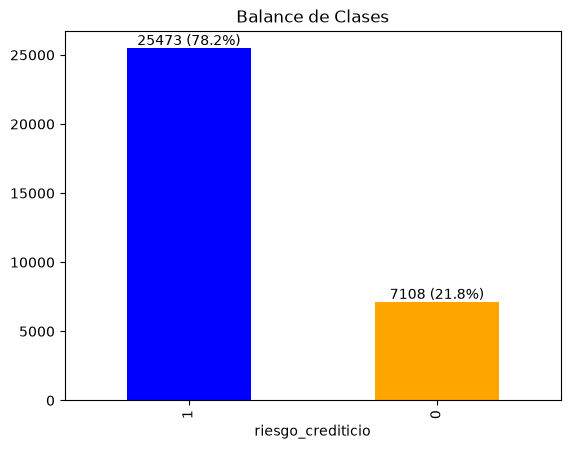

In [6]:
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(sampling_strategy='auto', random_state=SEED)

import pandas as pd
import matplotlib.pyplot as plt

# Guardamos el gráfico en una variable (ax)
class_counts = pd.Series(y).value_counts()
ax = class_counts.plot(kind='bar', color=['blue', 'orange'])

# Agregamos las etiquetas iterando sobre los contenedores de las barras
total_registros = class_counts.sum()
labels = [f'{count} ({count / total_registros:.1%})' for count in class_counts]
ax.bar_label(ax.containers[0], labels=labels)

plt.title('Balance de Clases')
plt.show()

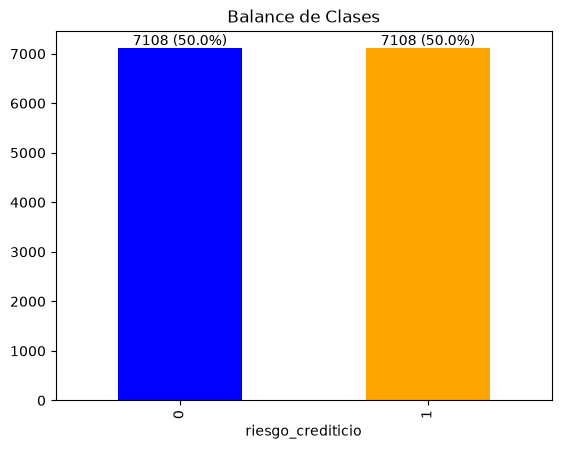

In [7]:
X_resampled, y_resampled = rus.fit_resample(X, y)

# Guardamos el gráfico en una variable (ax)
class_counts = pd.Series(y_resampled).value_counts()
ax = class_counts.plot(kind='bar', color=['blue', 'orange'])

# Agregamos las etiquetas iterando sobre los contenedores de las barras
total_registros = class_counts.sum()
labels = [f'{count} ({count / total_registros:.1%})' for count in class_counts]
ax.bar_label(ax.containers[0], labels=labels)

plt.title('Balance de Clases')
plt.show()

## Entrenamiento

In [8]:
import numpy as np
import optuna

from sklearn.ensemble import RandomForestClassifier
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

SEED = 42
n_classes = len(np.unique(y_train))

X_res, y_res = rus.fit_resample(X_train, y_train)
print(f"Clases balanceadas: {np.unique(y_res, return_counts=True)}")

X_res = X_train
y_res = y_train


#Optuna optimization for XGBoost, LightGBM, and Random Forest
def objective_xgb(trial):

    pesos_clase = y_res.value_counts()[0] / y_res.value_counts()[1]  # Ajuste de pesos para la clase minoritaria (riesgo)

    params = {
        'n_estimators': trial.suggest_int('n_estimators', 60, 200),
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 1.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 1.0, log=True),
        'random_state': SEED,
        'n_jobs': -1,
        'tree_method': 'hist',
        'eval_metric': 'logloss',
        'scale_pos_weight': pesos_clase
    }
    if n_classes == 2:
        params['objective'] = 'binary:logistic'
    else:
        params['objective'] = 'multi:softprob'
        params['num_class'] = n_classes

    model = XGBClassifier(**params)
    cls = Pipeline(steps=[('preprocessor', pipeline), ('classifier', model)])
    cls.fit(X_res, y_res)
    pred = cls.predict(X_test)
    return f1_score(y_test, pred)


def objective_lgb(trial):

    pesos_clase = y_res.value_counts()[0] / y_res.value_counts()[1]
                                                                 
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 60, 220),
        'max_depth': trial.suggest_int('max_depth', -1, 10),
        'num_leaves': trial.suggest_int('num_leaves', 15, 127),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 1.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 1.0, log=True),
        'random_state': SEED,
        'n_jobs': -1,
        'verbosity': -1,
        'num_threads': 0,
        'scale_pos_weight': pesos_clase
    }
    if n_classes == 2:
        params['objective'] = 'binary'
    else:
        params['objective'] = 'multiclass'
        params['num_class'] = n_classes

    model = LGBMClassifier(**params)
    cls = Pipeline(steps=[('preprocessor', pipeline), ('classifier', model)])
    cls.fit(X_res, y_res)
    pred = cls.predict(X_test)
    return f1_score(y_test, pred)


def objective_rf(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'random_state': SEED,
        'n_jobs': -1,
        'class_weight': {0: 5, 1: 1}
    }

    model = RandomForestClassifier(**params)
    cls = Pipeline(steps=[('preprocessor', pipeline), ('classifier', model)])
    cls.fit(X_res, y_res)
    pred = cls.predict(X_test)
    return f1_score(y_test, pred)

Clases balanceadas: (array([0, 1]), array([4265, 4265]))


In [9]:
# Train models
N_TRIALS = 30

study_xgb = optuna.create_study(direction='maximize', study_name='xgb_study')
study_xgb.optimize(objective_xgb, n_trials=N_TRIALS, timeout=120, show_progress_bar=False)

study_lgb = optuna.create_study(direction='maximize', study_name='lgb_study')
study_lgb.optimize(objective_lgb, n_trials=N_TRIALS, timeout=120, show_progress_bar=False)

study_rf = optuna.create_study(direction='maximize', study_name='rf_study')
study_rf.optimize(objective_rf, n_trials=N_TRIALS, timeout=120, show_progress_bar=False)

best_xgb_params = {**study_xgb.best_params, 'random_state': SEED, 'n_jobs': -1, 'tree_method': 'hist', 'eval_metric': 'logloss'}
if n_classes == 2:
    best_xgb_params['objective'] = 'binary:logistic'
else:
    best_xgb_params['objective'] = 'multi:softprob'
    best_xgb_params['num_class'] = n_classes
best_xgb = Pipeline(steps=[('preprocessor', pipeline), ('classifier', XGBClassifier(**best_xgb_params))])
best_xgb.fit(X_train, y_train)

best_lgb_params = {**study_lgb.best_params, 'random_state': SEED, 'n_jobs': -1, 'verbosity': -1}
if n_classes == 2:
    best_lgb_params['objective'] = 'binary'
else:
    best_lgb_params['objective'] = 'multiclass'
    best_lgb_params['num_class'] = n_classes

best_lgb = Pipeline(steps=[('preprocessor', pipeline), ('classifier', LGBMClassifier(**best_lgb_params))])
best_lgb.fit(X_train, y_train)

best_rf_params = {**study_rf.best_params, 'random_state': SEED, 'n_jobs': -1}
best_rf = Pipeline(steps=[('preprocessor', pipeline), ('classifier', RandomForestClassifier(**best_rf_params))])  
best_rf.fit(X_train, y_train)

[I 2026-08-22 09:50:26,334] A new study created in memory with name: xgb_study
[I 2026-08-22 09:50:26,487] Trial 0 finished with value: 0.8966900702106319 and parameters: {'n_estimators': 94, 'max_depth': 4, 'learning_rate': 0.09742298973872623, 'subsample': 0.8763361156615334, 'colsample_bytree': 0.9803600836924447, 'reg_alpha': 6.84986268594428e-08, 'reg_lambda': 2.633394774256312e-05}. Best is trial 0 with value: 0.8966900702106319.
[I 2026-08-22 09:50:26,739] Trial 1 finished with value: 0.9055102446787349 and parameters: {'n_estimators': 139, 'max_depth': 6, 'learning_rate': 0.058545672761396994, 'subsample': 0.9446844964060146, 'colsample_bytree': 0.7890286365974128, 'reg_alpha': 6.856632159166749e-06, 'reg_lambda': 0.05051671300915635}. Best is trial 1 with value: 0.9055102446787349.
[I 2026-08-22 09:50:26,977] Trial 2 finished with value: 0.9035818200060198 and parameters: {'n_estimators': 183, 'max_depth': 4, 'learning_rate': 0.1568177488629975, 'subsample': 0.9632704862290564

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['ingresos','tipo_vivienda','anios_trabajo',...,'porcentaje_ingresos', 'historial_mora','historial_credito_anios']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to th

In [10]:
#xgboost best params
print("Best XGBoost parameters:", best_xgb_params)
#lightgbm best params
print("Best LightGBM parameters:", best_lgb_params)
#randomforest best params
print("Best Random Forest parameters:", best_rf_params)

Best XGBoost parameters: {'n_estimators': 200, 'max_depth': 7, 'learning_rate': 0.16386152008117338, 'subsample': 0.738962801947661, 'colsample_bytree': 0.9974087026567164, 'reg_alpha': 1.6951974413344641e-06, 'reg_lambda': 7.427107599758332e-08, 'random_state': 42, 'n_jobs': -1, 'tree_method': 'hist', 'eval_metric': 'logloss', 'objective': 'binary:logistic'}
Best LightGBM parameters: {'n_estimators': 74, 'max_depth': 9, 'num_leaves': 120, 'learning_rate': 0.02661756784008527, 'subsample': 0.9668940955694482, 'colsample_bytree': 0.9505154856022114, 'reg_alpha': 0.027767635980971265, 'reg_lambda': 2.579575357218593e-05, 'random_state': 42, 'n_jobs': -1, 'verbosity': -1, 'objective': 'binary'}
Best Random Forest parameters: {'n_estimators': 170, 'max_depth': 14, 'min_samples_split': 3, 'min_samples_leaf': 2, 'random_state': 42, 'n_jobs': -1}


In [11]:
pred_xgb_test = best_xgb.predict(X_val)
pred_lgb_test = best_lgb.predict(X_val)
pred_rf_test = best_rf.predict(X_val)

acc_xgb = accuracy_score(y_val, pred_xgb_test)
acc_lgb = accuracy_score(y_val, pred_lgb_test)
acc_rf = accuracy_score(y_val, pred_rf_test)

scores = {'xgboost': acc_xgb, 'lightgbm': acc_lgb, 'randomforest': acc_rf}
best_name = max(scores, key=scores.get)

if best_name == 'xgboost':
    print("El mejor modelo es XGBoost con una precisión de:", acc_xgb)
    best_model = best_xgb
elif best_name == 'lightgbm':
    print("El mejor modelo es LightGBM con una precisión de:", acc_lgb)
    best_model = best_lgb
else:
    print("El mejor modelo es Random Forest con una precisión de:", acc_rf)
    best_model = best_rf

best_model

El mejor modelo es XGBoost con una precisión de: 0.891804788213628


<ruta-del-proyecto>/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['ingresos','tipo_vivienda','anios_trabajo',...,'porcentaje_ingresos', 'historial_mora','historial_credito_anios']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to th

In [12]:
from sklearn.metrics import classification_report

pred_val = best_model.predict(X_val)

assert len(pred_val) == len(X_val), 'Predicciones y X_val no coinciden en longitud.'
assert not np.isnan(np.asarray(pred_val, dtype=float)).any(), 'Predicciones con NaN.'

print('=== Resultados en x_val ===')
print(f'XGBoost accuracy: {acc_xgb:.8f}')
print(f'LightGBM accuracy: {acc_lgb:.8f}')
print(f'RandomForest accuracy: {acc_rf:.8f}')
print(f'Mejor modelo: {best_name}')
print(f'Predicciones en x_val generadas correctamente: {len(pred_val)} de {len(X_val)}')

if y_val is not None:
    acc_val = accuracy_score(y_val, pred_val)
    print(f'Accuracy en x_val: {acc_val:.8f}')
    print(classification_report(y_val, pred_val))

=== Resultados en x_val ===
XGBoost accuracy: 0.89180479
LightGBM accuracy: 0.88566605
RandomForest accuracy: 0.88382443
Mejor modelo: xgboost
Predicciones en x_val generadas correctamente: 6516 de 6516
Accuracy en x_val: 0.89180479
              precision    recall  f1-score   support

           0       0.84      0.62      0.71      1421
           1       0.90      0.97      0.93      5095

    accuracy                           0.89      6516
   macro avg       0.87      0.79      0.82      6516
weighted avg       0.89      0.89      0.89      6516



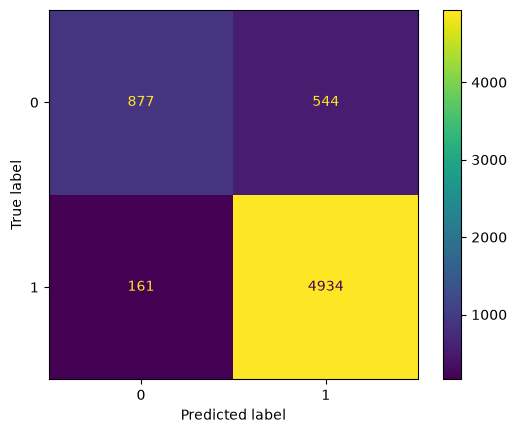

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = best_model.predict(X_val)
cm_xgb = confusion_matrix(
    y_val,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb
)

disp.plot()

plt.show()

In [14]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, precision_score, recall_score
import numpy as np

# Definir los modelos y sus estudios correspondientes
modelos_info = [
    {"nombre": "XGBoost", "model": best_xgb, "study": study_xgb},
    {"nombre": "LightGBM", "model": best_lgb, "study": study_lgb},
    {"nombre": "Random Forest", "model": best_rf, "study": study_rf}
]

resultados = []

for item in modelos_info:
    name = item["nombre"]
    model = item["model"]
    study = item["study"]
    
    # 1. Obtener el mejor trial de Optuna
    best_trial = study.best_trial.number
    
    # 2. Generar predicciones en X_val
    preds = model.predict(X_val)
    probs = model.predict_proba(X_val)[:, 1] if hasattr(model, "predict_proba") else preds

    # 3. Calcular Métricas
    acc = accuracy_score(y_val, preds)
    f1 = f1_score(y_val, preds)
    prec = precision_score(y_val, preds)
    rec = recall_score(y_val, preds)
    
    # ROC AUC (Asegurarse de manejar casos donde solo hay una clase en test, aunque raro con stratified)
    try:
        aroc = roc_auc_score(y_val, probs)
    except:
        aroc = np.nan

    resultados.append({
        "Modelo": name,
        "Mejor Trial": best_trial,
        "Accuracy": round(acc, 4),
        "F1-Score": round(f1, 4),
        "ROC AUC": round(aroc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4)
    })

# Crear DataFrame para visualización
df_comparativa = pd.DataFrame(resultados)

# Estilizar la tabla
print("Comparativa de Modelos Entrenados (Conjunto de Prueba)")
display(df_comparativa.sort_values(by="F1-Score", ascending=False).style.background_gradient(cmap='Greens', subset=['Accuracy', 'F1-Score', 'ROC AUC']))

Comparativa de Modelos Entrenados (Conjunto de Prueba)


<ruta-del-proyecto>/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
<ruta-del-proyecto>/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Modelo,Mejor Trial,Accuracy,F1-Score,ROC AUC,Precision,Recall
0,XGBoost,26,0.891800,0.933300,0.894800,0.900700,0.968400
1,LightGBM,25,0.885700,0.931400,0.875900,0.877200,0.992700
2,Random Forest,26,0.883800,0.929900,0.868400,0.880400,0.985300


## Guardar modelo para ser utilizado en el sistema con mlflow

In [15]:
import mlflow
import mlflow.sklearn
import os
import shutil

# Definir la ruta de la carpeta donde se guardará el modelo
model_dir = os.path.abspath("../models")
model_path = os.path.join(model_dir, "best_model")

# Crear el directorio base si no existe
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Eliminar la carpeta específica del modelo si ya existe para evitar errores de mlflow.save_model
if os.path.exists(model_path):
    shutil.rmtree(model_path)

# IMPORTANTE: best_model ya es un Pipeline que incluye el preprocesador.
# No necesitamos envolverlo nuevamente.
# Guardar el modelo utilizando mlflow con cloudpickle para soportar funciones personalizadas o clases del notebook
mlflow.sklearn.save_model(
    sk_model=best_model,
    path=model_path,
    serialization_format='cloudpickle'
)

print(f"Modelo guardado exitosamente en: {model_path}")

2026/08/22 09:51:17 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Modelo guardado exitosamente en: <ruta-del-proyecto>/models/best_model


## Cargar modelo y realizar predicciones
Cargamos el modelo guardado previamente y lo probamos con un conjunto de datos CSV.

In [16]:
import pandas as pd
import mlflow.sklearn
import os

# Definir la ruta del modelo guardado
model_path = os.path.abspath("../models/best_model")

# Cargar el modelo
loaded_model = mlflow.sklearn.load_model(model_path)

loaded_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['ingresos','tipo_vivienda','anios_trabajo',...,'porcentaje_ingresos', 'historial_mora','historial_credito_anios']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to th

In [17]:


# Mapear la variable objetivo (riesgo) para compatibilidad con las siguientes celdas
# 1 = Bueno (0), 2 = Malo (1)
df_test = X_test.copy()
df_test['riesgo'] = y_test

# Extraer las columnas requeridas directamente del modelo entrenado
try:
    required_features = loaded_model.feature_names_in_.tolist()
    print("Columnas requeridas por el modelo:", required_features)
    
    # Filtrar el dataframe para que solo contenga las columnas necesarias en el orden correcto
    X_input = df_test[required_features]
    
    # Realizar predicciones
    predictions = loaded_model.predict(X_input)
    
    # Agregar las predicciones al dataframe original para visualizar
    df_test['prediccion_riesgo'] = predictions
    
    print("\nPredicciones realizadas con éxito. Primeras 5 filas:")
    display(df_test[['riesgo', 'prediccion_riesgo']].head())
except Exception as e:
    print(f"\nError al realizar las predicciones: {e}")
    print("\nNota: Verifica que los nombres de las columnas coincidan exactamente con los usados en el entrenamiento.")

Columnas requeridas por el modelo: ['ingresos', 'tipo_vivienda', 'anios_trabajo', 'motivo_prestamo', 'monto_prestamo', 'porcentaje_ingresos', 'historial_mora', 'historial_credito_anios']

Predicciones realizadas con éxito. Primeras 5 filas:


,riesgo,prediccion_riesgo
3711,1,1
14700,1,1
18918,1,1
15798,1,1
6444,0,1


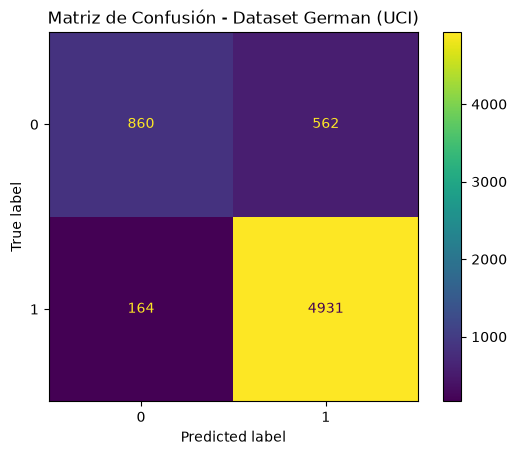

In [18]:
# Matriz de confusión para las predicciones en el conjunto del dataset German
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Usamos la columna 'riesgo' que ya fue mapeada en la celda anterior
y_true = df_test["riesgo"]
cm_test = confusion_matrix(y_true, df_test['prediccion_riesgo'])
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
disp_test.plot()
plt.title("Matriz de Confusión - Dataset German (UCI)")
plt.show()

In [28]:
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score

print("Reporte de clasificación para el modelo cargado (Dataset German)")
y_true = df_test["riesgo"]
print(classification_report(y_true, df_test['prediccion_riesgo']))

acc_test = accuracy_score(y_true, df_test['prediccion_riesgo'])
print(f'Accuracy total: {acc_test:.8f}')

auc_test = roc_auc_score(y_true, df_test['prediccion_riesgo'])
print(f'AUC total: {auc_test:.8f}')

Reporte de clasificación para el modelo cargado (Dataset German)
              precision    recall  f1-score   support

           0       0.84      0.60      0.70      1422
           1       0.90      0.97      0.93      5095

    accuracy                           0.89      6517
   macro avg       0.87      0.79      0.82      6517
weighted avg       0.89      0.89      0.88      6517

Accuracy total: 0.88859905
AUC total: 0.78629679


In [20]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, precision_score, recall_score
import numpy as np

# Definir los modelos y sus estudios correspondientes
modelos_info = [
    {"nombre": "XGBoost", "model": best_xgb, "study": study_xgb},
    {"nombre": "LightGBM", "model": best_lgb, "study": study_lgb},
    {"nombre": "Random Forest", "model": best_rf, "study": study_rf}
]

resultados = []

for item in modelos_info:
    name = item["nombre"]
    model = item["model"]
    study = item["study"]
    
    # 1. Obtener el mejor trial de Optuna
    best_trial = study.best_trial.number
    
    # 2. Generar predicciones en X_test
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else preds

    # 3. Calcular Métricas
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    
    # ROC AUC (Asegurarse de manejar casos donde solo hay una clase en test, aunque raro con stratified)
    try:
        aroc = roc_auc_score(y_test, probs)
    except:
        aroc = np.nan

    resultados.append({
        "Modelo": name,
        "Mejor Trial": best_trial,
        "Accuracy": round(acc, 4),
        "F1-Score": round(f1, 4),
        "ROC AUC": round(aroc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4)
    })

# Crear DataFrame para visualización
df_comparativa = pd.DataFrame(resultados)

# Estilizar la tabla
print("Comparativa de Modelos Entrenados (Conjunto de Prueba)")
display(df_comparativa.sort_values(by="F1-Score", ascending=False).style.background_gradient(cmap='Greens', subset=['Accuracy', 'F1-Score', 'ROC AUC']))

Comparativa de Modelos Entrenados (Conjunto de Prueba)


<ruta-del-proyecto>/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
<ruta-del-proyecto>/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Modelo,Mejor Trial,Accuracy,F1-Score,ROC AUC,Precision,Recall
0,XGBoost,26,0.888600,0.931400,0.894200,0.897700,0.967800
1,LightGBM,25,0.882300,0.929600,0.869100,0.873100,0.993900
2,Random Forest,26,0.882800,0.929400,0.866500,0.877700,0.987600


## Prueba estadística entre modelos (conjunto de prueba)

Compara XGBoost frente a LightGBM y Random Forest sobre el mismo `X_test`: prueba exacta de McNemar (errores pareados), intervalos de confianza bootstrap del 95 % para cada métrica y para la diferencia de AUC calculada con probabilidades (`predict_proba`), con corrección de Holm. También muestra por qué el AUC con etiquetas duras (`predict`) difiere del AUC con probabilidades.

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import binomtest
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

modelos = {"XGBoost": best_xgb, "LightGBM": best_lgb, "Random Forest": best_rf}
y_true = np.asarray(y_test)
pred = {n: np.asarray(m.predict(X_test)) for n, m in modelos.items()}
prob = {n: np.asarray(m.predict_proba(X_test)[:, 1]) for n, m in modelos.items()}

# 1) AUC con probabilidades vs. AUC con etiquetas duras
for n in modelos:
    print(f"{n}: AUC (probabilidades) = {roc_auc_score(y_true, prob[n]):.4f} | AUC (etiquetas duras) = {roc_auc_score(y_true, pred[n]):.4f}")

# 2) McNemar exacto: XGBoost vs. cada alternativa
def mcnemar_exacto(y, a, b):
    a_ok, b_ok = (a == y), (b == y)
    n01 = int(np.sum(a_ok & ~b_ok))   # acierta A, falla B
    n10 = int(np.sum(~a_ok & b_ok))   # falla A, acierta B
    n = n01 + n10
    p = binomtest(n01, n, 0.5).pvalue if n > 0 else 1.0
    return n01, n10, p

filas = []
for rival in ["LightGBM", "Random Forest"]:
    n01, n10, p = mcnemar_exacto(y_true, pred["XGBoost"], pred[rival])
    filas.append({"Comparación": f"XGBoost vs {rival}", "XGB acierta/rival falla": n01, "XGB falla/rival acierta": n10, "p (McNemar)": p})
df_mc = pd.DataFrame(filas)
# Corrección de Holm (m = 2 comparaciones)
orden = df_mc["p (McNemar)"].sort_values().index
holm, previo = {}, 0.0
for k, idx in enumerate(orden):
    previo = max(previo, min(1.0, (len(orden) - k) * df_mc.loc[idx, "p (McNemar)"]))
    holm[idx] = previo
df_mc["p ajustado (Holm)"] = pd.Series(holm)
display(df_mc)

# 3) Bootstrap pareado (mismas muestras para los tres modelos)
rng = np.random.default_rng(42)
B = 1000
n = len(y_true)
metricas = {"Accuracy": accuracy_score, "Precision": precision_score, "Recall": recall_score, "F1": f1_score}
boot = {m: {k: [] for k in modelos} for m in list(metricas) + ["AUC"]}
dauc = {"LightGBM": [], "Random Forest": []}
for _ in range(B):
    idx = rng.integers(0, n, n)
    yb = y_true[idx]
    if len(np.unique(yb)) < 2:
        continue
    auc_b = {}
    for nombre in modelos:
        for m, f in metricas.items():
            boot[m][nombre].append(f(yb, pred[nombre][idx]))
        auc_b[nombre] = roc_auc_score(yb, prob[nombre][idx])
        boot["AUC"][nombre].append(auc_b[nombre])
    for rival in dauc:
        dauc[rival].append(auc_b["XGBoost"] - auc_b[rival])

resumen = []
for m in boot:
    for nombre in modelos:
        v = np.array(boot[m][nombre])
        resumen.append({"Métrica": m, "Modelo": nombre, "Media": v.mean(), "IC95 inf": np.percentile(v, 2.5), "IC95 sup": np.percentile(v, 97.5)})
display(pd.DataFrame(resumen).round(4))

for rival, v in dauc.items():
    v = np.array(v)
    print(f"AUC XGBoost - {rival}: media={v.mean():.4f}, IC95%=[{np.percentile(v, 2.5):.4f}, {np.percentile(v, 97.5):.4f}]")


## Verificación de features

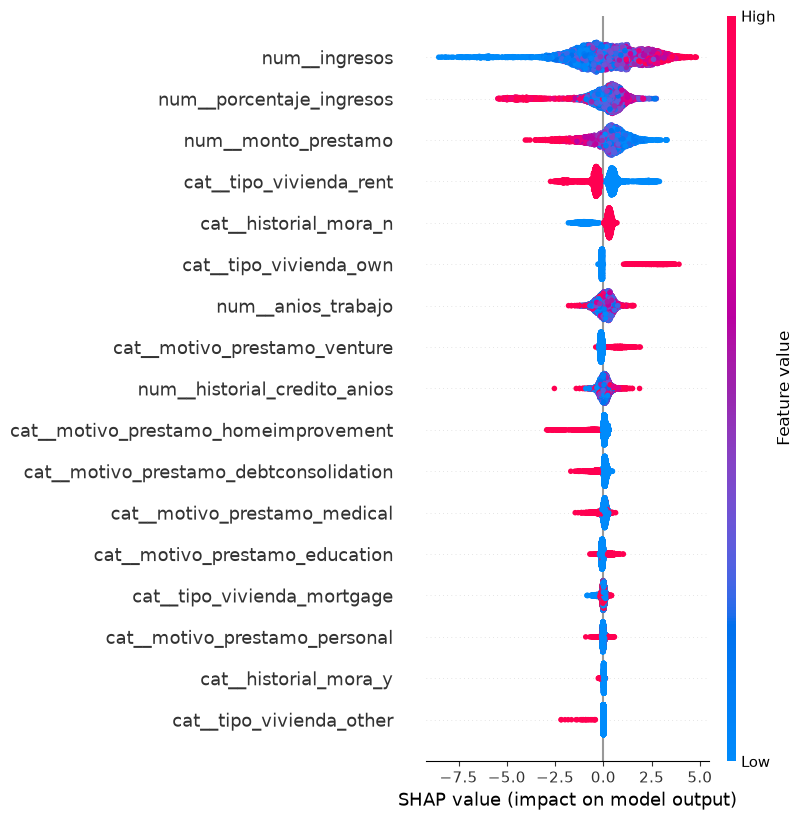

In [21]:
# SHAP Explanation para el Pipeline
import shap
import numpy as np

# 1. Extraer el preprocesador y el modelo del Pipeline
preprocessor = loaded_model.named_steps['preprocessor']
classifier = loaded_model.named_steps['classifier']

# 2. Transformar los datos (usamos X_val que ya tiene las columnas correctas)
# Si X_val no existe en este scope (ej: si reiniciaste el kernel), lo recreamos desde df_test
if 'X_val' not in locals():
    required_features = loaded_model.feature_names_in_.tolist()
    X_val = df_test[required_features]

X_val_transformed = preprocessor.transform(X_val)

# 3. Obtener los nombres de las columnas transformadas
try:
    # Intentar obtener nombres de features out directamente
    feature_names = preprocessor.get_feature_names_out()
except Exception as e:
    print(f"Advertencia: No se pudo obtener feature_names_out automáticamente ({e}). Intentando construcción manual.")
    # Construcción manual de nombres para OneHotEncoder y otros
    feature_names = []
    for name, trans, cols in preprocessor.transformers_:
        if name == 'remainder' and trans == 'drop':
            continue
        if hasattr(trans, 'get_feature_names_out'):
            feature_names.extend(trans.get_feature_names_out(cols))
        else:
            feature_names.extend(cols)

# 4. Crear el explicador de SHAP
# Para modelos de árboles (XGB, LGBM, RandomForest) usamos TreeExplainer
if any(model_name in str(type(classifier)) for model_name in ["XGB", "LGBM", "RandomForest"]):
    explainer = shap.TreeExplainer(classifier)
    shap_values = explainer.shap_values(X_val_transformed)
else:
    # Fallback para otros modelos
    explainer = shap.Explainer(classifier, X_val_transformed)
    shap_values = explainer(X_val_transformed)

# 5. Graficar
# Para clasificación binaria, shap_values suele ser una lista [val_clase0, val_clase1] o un array
if isinstance(shap_values, list):
    # En XGBoost/LGBM/RF shap_values[1] es para la clase positiva
    shap_val_to_plot = shap_values[1] if len(shap_values) > 1 else shap_values[0]
elif isinstance(shap_values, np.ndarray) and len(shap_values.shape) == 3:
    # Algunos explicadores devuelven [n_samples, n_features, n_classes]
    shap_val_to_plot = shap_values[:, :, 1]
else:
    shap_val_to_plot = shap_values

shap.summary_plot(
    shap_val_to_plot,
    X_val_transformed,
    feature_names=feature_names
)

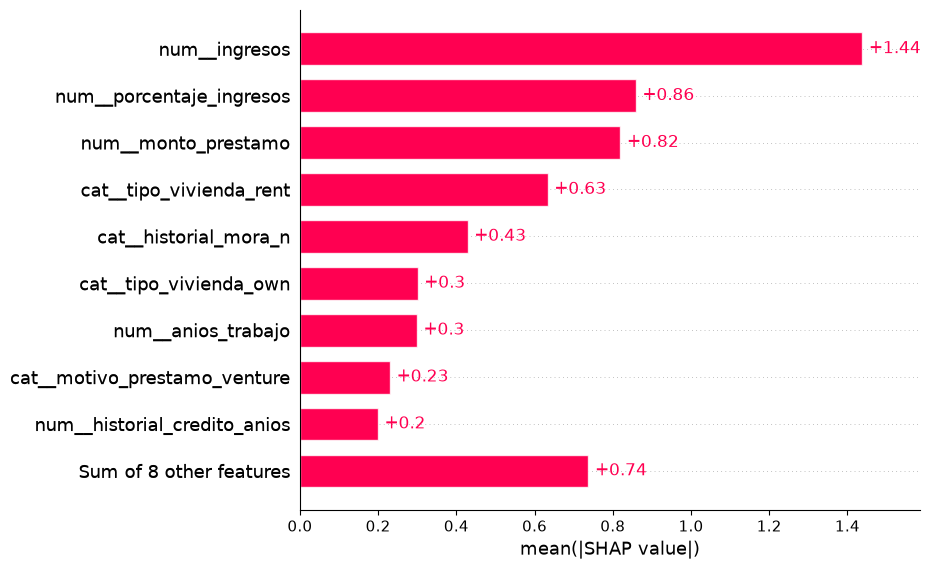

In [22]:
# debemos crear un objeto Explanation para que plots.bar funcione correctamente con feature_names
if isinstance(shap_val_to_plot, np.ndarray):
    shap_exp = shap.Explanation(
        values=shap_val_to_plot, 
        data=X_val_transformed, 
        feature_names=feature_names
    )
    shap.plots.bar(shap_exp, max_display=10)
else:
    # Si ya es un objeto Explanation (lo que devuelve el Explainer genérico)
    shap.plots.bar(shap_val_to_plot, max_display=10)

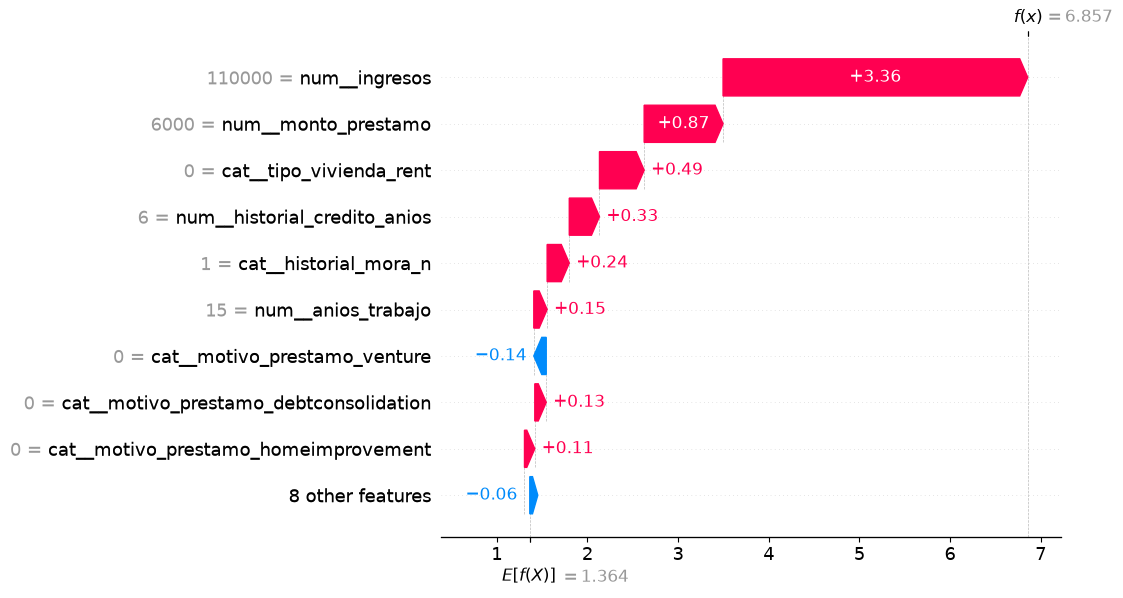

In [23]:
row_index = 0  # Índice de la fila a explicar

if isinstance(shap_val_to_plot, np.ndarray):
    # Si shap_values es una matriz [n_ejemplos, n_características]
    shap_exp = shap.Explanation(
        values=shap_val_to_plot[row_index], 
        base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value,
        data=X_val_transformed[row_index], 
        feature_names=feature_names
    )
    shap.plots.waterfall(shap_exp, max_display=10)
else:
    # Si ya es un objeto Explanation
    shap.plots.waterfall(shap_val_to_plot[row_index], max_display=10)

In [24]:
# Predicción manual: cambia los valores en el diccionario 'datos_usuario'
import pandas as pd
import shap
import numpy as np
import matplotlib.pyplot as plt

# Definimos los datos del usuario basados en las columnas del modelo entrenado (Kaggle dataset)
# Nota: 'edad', 'tasa_interes' y 'grado_prestamo' fueron excluidos por Sesgo/Leakage
datos_usuario = {
    'ingresos': [35000],
    'tipo_vivienda': ['RENT'],
    'anios_trabajo': [4],
    'motivo_prestamo': ['EDUCATION'],
    'monto_prestamo': [5000],
    'porcentaje_ingresos': [0.14],
    'historial_mora': ['N'],
    'historial_credito_anios': [2]
}

# Convertir a DataFrame con los nombres de columnas correctos
X_manual = pd.DataFrame(datos_usuario)

# Realizar la predicción usando el mejor modelo encontrado
# Asegurarse de que el modelo esté cargado (loaded_model)
try:
    prediction = loaded_model.predict(X_manual)
    
    # Mapeo de la predicción a etiquetas legibles
    # Tras la inversión: 0 = RIESGO, 1 = APROBADO
    class_names = ['RIESGO', 'APROBADO']
    resultado = class_names[prediction[0]]
    
    print(f"Predicción para los datos ingresados: {resultado} (Clase: {prediction[0]})")
    
    # Opcional: ver probabilidades si el modelo lo permite
    if hasattr(loaded_model, "predict_proba"):
        probs = loaded_model.predict_proba(X_manual)
        print(f"Probabilidades: RIESGO: {probs[0][0]:.2f}, APROBADO: {probs[0][1]:.2f}")
except Exception as e:
    print(f"Error al predecir: {e}")

Predicción para los datos ingresados: APROBADO (Clase: 1)
Probabilidades: RIESGO: 0.04, APROBADO: 0.96



=== Explicación SHAP de la predicción ===


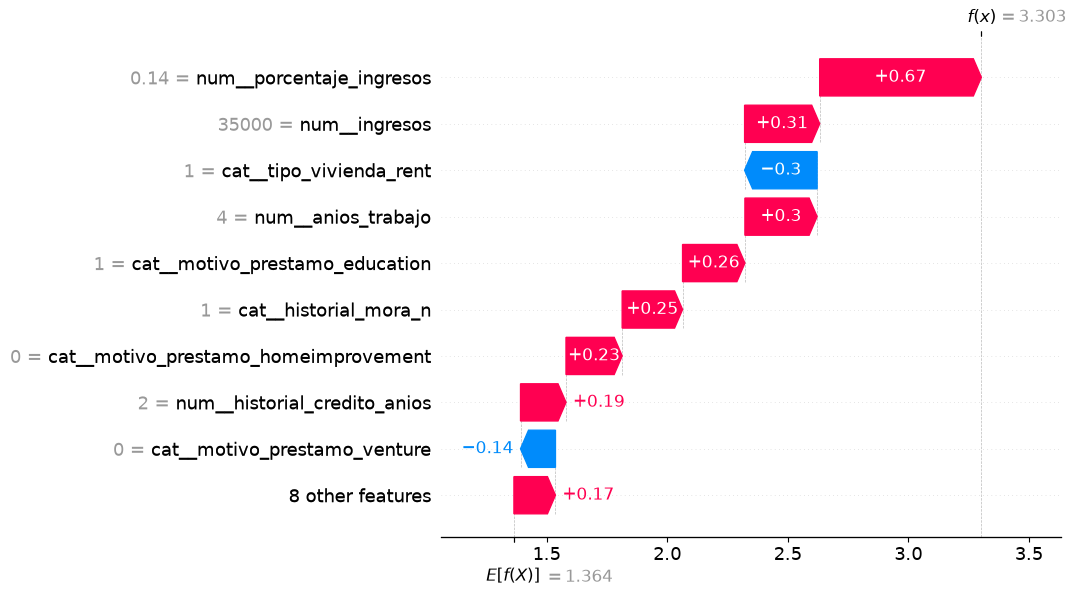

In [25]:
# --- EXPLICACIÓN SHAP PARA LA PREDICCIÓN MANUAL ---
print("\n=== Explicación SHAP de la predicción ===")

# 1. Extraer componentes del pipeline
preprocessor = loaded_model.named_steps['preprocessor']
classifier = loaded_model.named_steps['classifier']

# 2. Transformar los datos manuales
X_manual_transformed = preprocessor.transform(X_manual)

# 3. Obtener nombres de características
try:
    feature_names = preprocessor.get_feature_names_out()
except:
    feature_names = [f"f_{i}" for i in range(X_manual_transformed.shape[1])]

# 4. Crear explicador y calcular SHAP values
if "XGB" in str(type(classifier)) or "LGBM" in str(type(classifier)):
    explainer = shap.TreeExplainer(classifier)
    shap_values = explainer.shap_values(X_manual_transformed)
else:
    # Fallback para modelos lineales (usar una referencia para Background)
    # Aquí usamos X_train_transformed si está disponible, o simplemente Explainer genérico
    explainer = shap.Explainer(classifier, preprocessor.transform(X_train[:100]))
    shap_values = explainer(X_manual_transformed)

# 5. Formatear para Waterfall plot
# Si es una lista (XGB/LGBM), tomamos la clase 1 (APROBADO)
if isinstance(shap_values, list):
    sv = shap_values[1][0] if len(shap_values) > 1 else shap_values[0][0]
    base_val = explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value
elif hasattr(shap_values, "values"): # Objeto Explanation
    sv = shap_values.values[0]
    base_val = shap_values.base_values[0]
else:
    sv = shap_values[0]
    base_val = explainer.expected_value

# Crear objeto Explanation para el gráfico
exp = shap.Explanation(
    values=sv,
    base_values=base_val,
    data=X_manual_transformed[0],
    feature_names=feature_names
)

# Graficar
shap.plots.waterfall(exp, max_display=10)
plt.show()

In [26]:
import pandas as pd

# 1. Crear el DataFrame extrayendo los datos de tu objeto 'exp'
df_shap = pd.DataFrame({
    'Feature': exp.feature_names,
    'Valor Real': exp.data,
    'Impacto SHAP (Contribución)': exp.values
})

# 2. (Opcional) Ordenar por impacto para ver qué influyó más (de mayor a menor)
df_shap = df_shap.sort_values(by='Impacto SHAP (Contribución)', key=abs, ascending=False)

# 3. Mostrar la tabla
print(f"Valor Base del Modelo: {exp.base_values}")
display(df_shap) # Si estás en Jupyter Notebook, usa display(). Si no, usa print(df_shap)


Valor Base del Modelo: 1.3642010688781738


,Feature,Valor Real,Impacto SHAP (Contribución)
3,num__porcentaje_ingresos,0.14,0.670408
0,num__ingresos,35000.00,0.311381
8,cat__tipo_vivienda_rent,1.00,-0.300683
1,num__anios_trabajo,4.00,0.299424
10,cat__motivo_prestamo_education,1.00,0.258583
15,cat__historial_mora_n,1.00,0.250469
11,cat__motivo_prestamo_homeimprovement,0.00,0.232969
4,num__historial_credito_anios,2.00,0.188552
14,cat__motivo_prestamo_venture,0.00,-0.144758
12,cat__motivo_prestamo_medical,0.00,0.098823


In [29]:
# Estilo visual para resaltar impactos positivos y negativos
df_shap.style.bar(subset=['Impacto SHAP (Contribución)'], align='mid', color=['#d65f5f', '#5fba7d'])

,Feature,Valor Real,Impacto SHAP (Contribución)
3,num__porcentaje_ingresos,0.140000,0.670408
0,num__ingresos,35000.000000,0.311381
8,cat__tipo_vivienda_rent,1.000000,-0.300683
1,num__anios_trabajo,4.000000,0.299424
10,cat__motivo_prestamo_education,1.000000,0.258583
15,cat__historial_mora_n,1.000000,0.250469
11,cat__motivo_prestamo_homeimprovement,0.000000,0.232969
4,num__historial_credito_anios,2.000000,0.188552
14,cat__motivo_prestamo_venture,0.000000,-0.144758
12,cat__motivo_prestamo_medical,0.000000,0.098823


In [30]:
import time

# Reutiliza variables existentes del notebook
best_ml = globals().get("best_ml", globals().get("best_model", None))
if best_ml is None:
    raise NameError("No existe 'best_ml' ni 'best_model' en memoria.")

if "X_manual" in globals():
    X_for_model = X_manual
elif "X_input" in globals():
    X_for_model = X_input
else:
    raise NameError("No existe 'X_manual' ni 'X_input' en memoria para inferencia.")

if "X_manual_transformed" not in globals():
    raise NameError("No existe 'X_manual_transformed' en memoria para SHAP.")

if "explainer" not in globals():
    raise NameError("No existe 'explainer' en memoria para SHAP.")

# 1) Tiempo de ejecución del modelo (inferencia)
t0 = time.perf_counter()
_ = best_ml.predict_proba(X_for_model)
model_ms = (time.perf_counter() - t0) * 1000

# 2) Tiempo de ejecución de SHAP
t1 = time.perf_counter()
_ = explainer(X_manual_transformed)
shap_ms = (time.perf_counter() - t1) * 1000

print(f"best_ml (predict_proba): {model_ms:.3f} ms")
print(f"SHAP (explainer): {shap_ms:.3f} ms")

best_ml (predict_proba): 14.910 ms
SHAP (explainer): 3.417 ms
